# 5. Шинжилгээ ба дүгнэлт (Хэсэг 5)

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
P, R, F = ROOT / "data" / "processed", ROOT / "reports", ROOT / "figures"
def show(name):
    display(Image(filename=str(F / f"{name}.png"), width=760))

In [2]:
from src.charts.summary import VERDICT_PLAIN, verdict
hyp = pd.read_csv(R / "hypotheses.csv")
hyp.assign(дүгнэлт=[VERDICT_PLAIN[verdict(r)] for _, r in hyp.iterrows()])[["hid", "statement", "estimate", "ci_lo", "ci_hi", "дүгнэлт"]].round(3)

,hid,statement,estimate,ci_lo,ci_hi,дүгнэлт
0,H1,Гадаад тоглогч дотоод тоглогчоос илүү оноо авдаг,10.650,9.400,13.100,Батлагдсан
1,H2,Гэрийн талбайдаа тоглосон баг 50%-аас илүү ялдаг,0.465,0.400,0.532,Баттай биш
2,H3,Ялалтын 4 хүчин зүйлээс шидэлтийн оновч хамгий...,1.919,1.504,2.374,Батлагдсан
3,H4,Өндөр тоглогч илүү олон самбар авдаг,0.628,0.548,0.697,Батлагдсан
4,H5,"Багийн авсан, алдсан оноо ялалтын хувийн талаа...",0.886,0.792,0.942,Батлагдсан


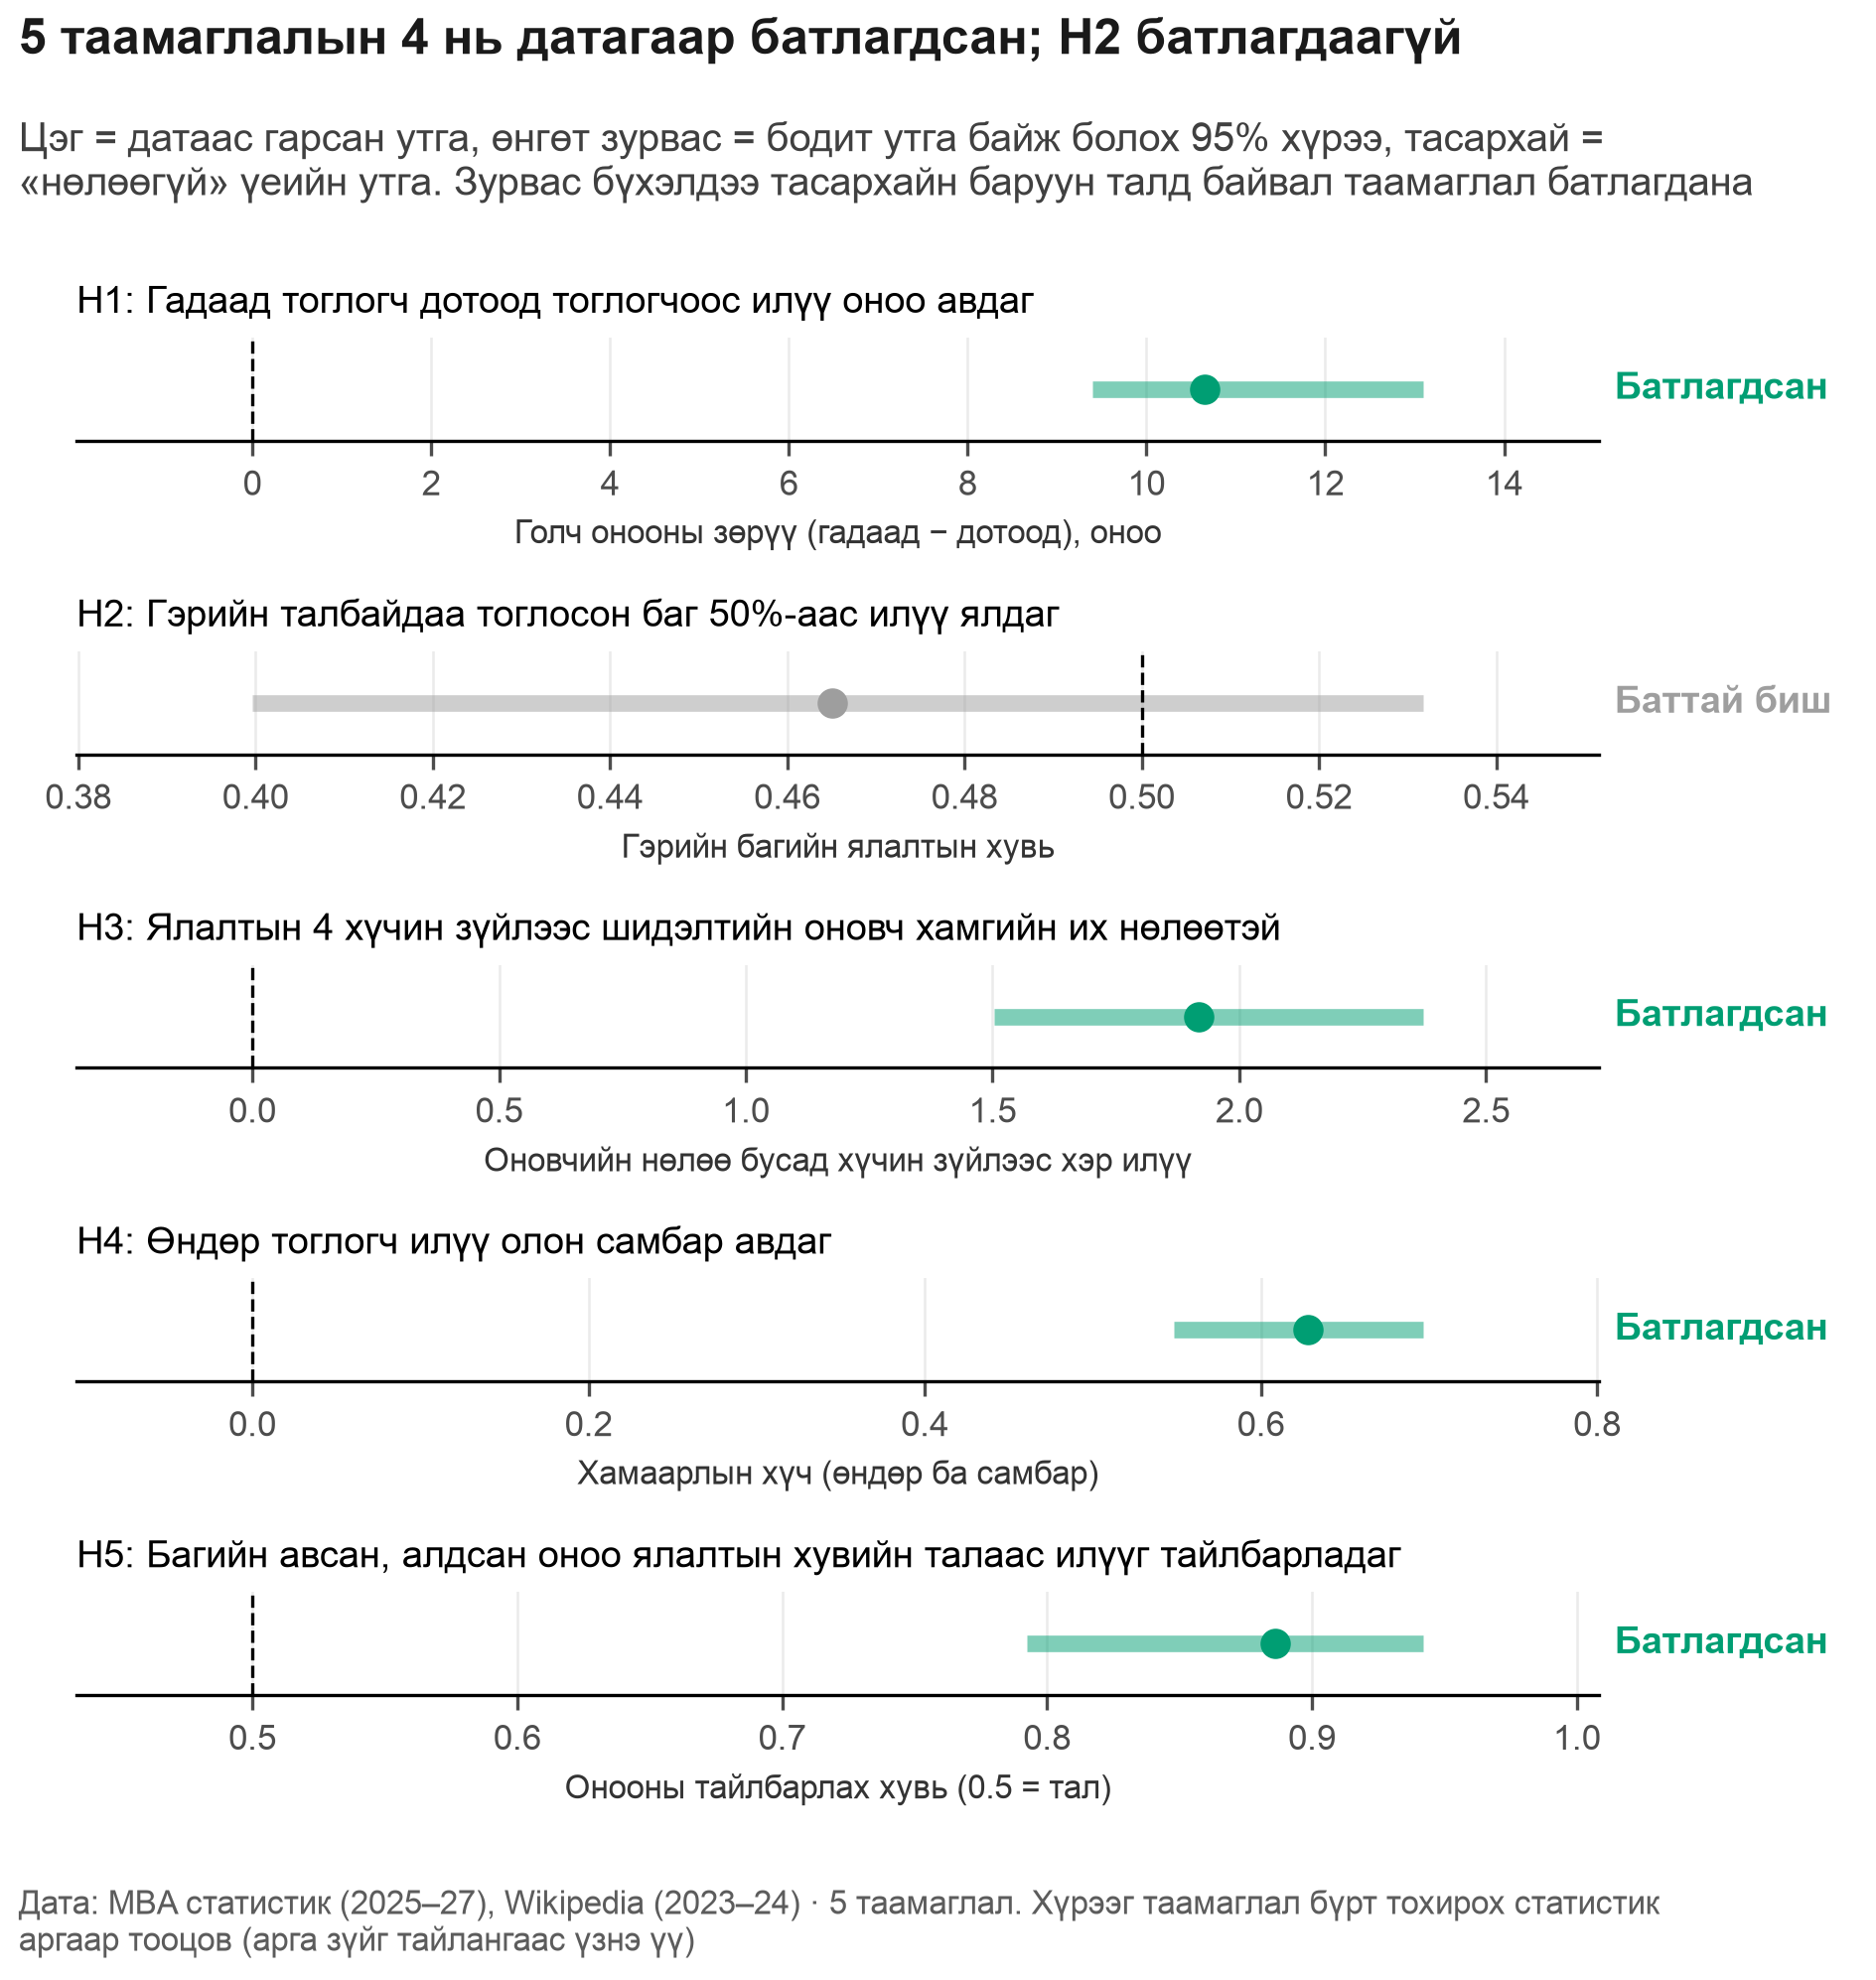

In [3]:
show("U05_hypotheses")

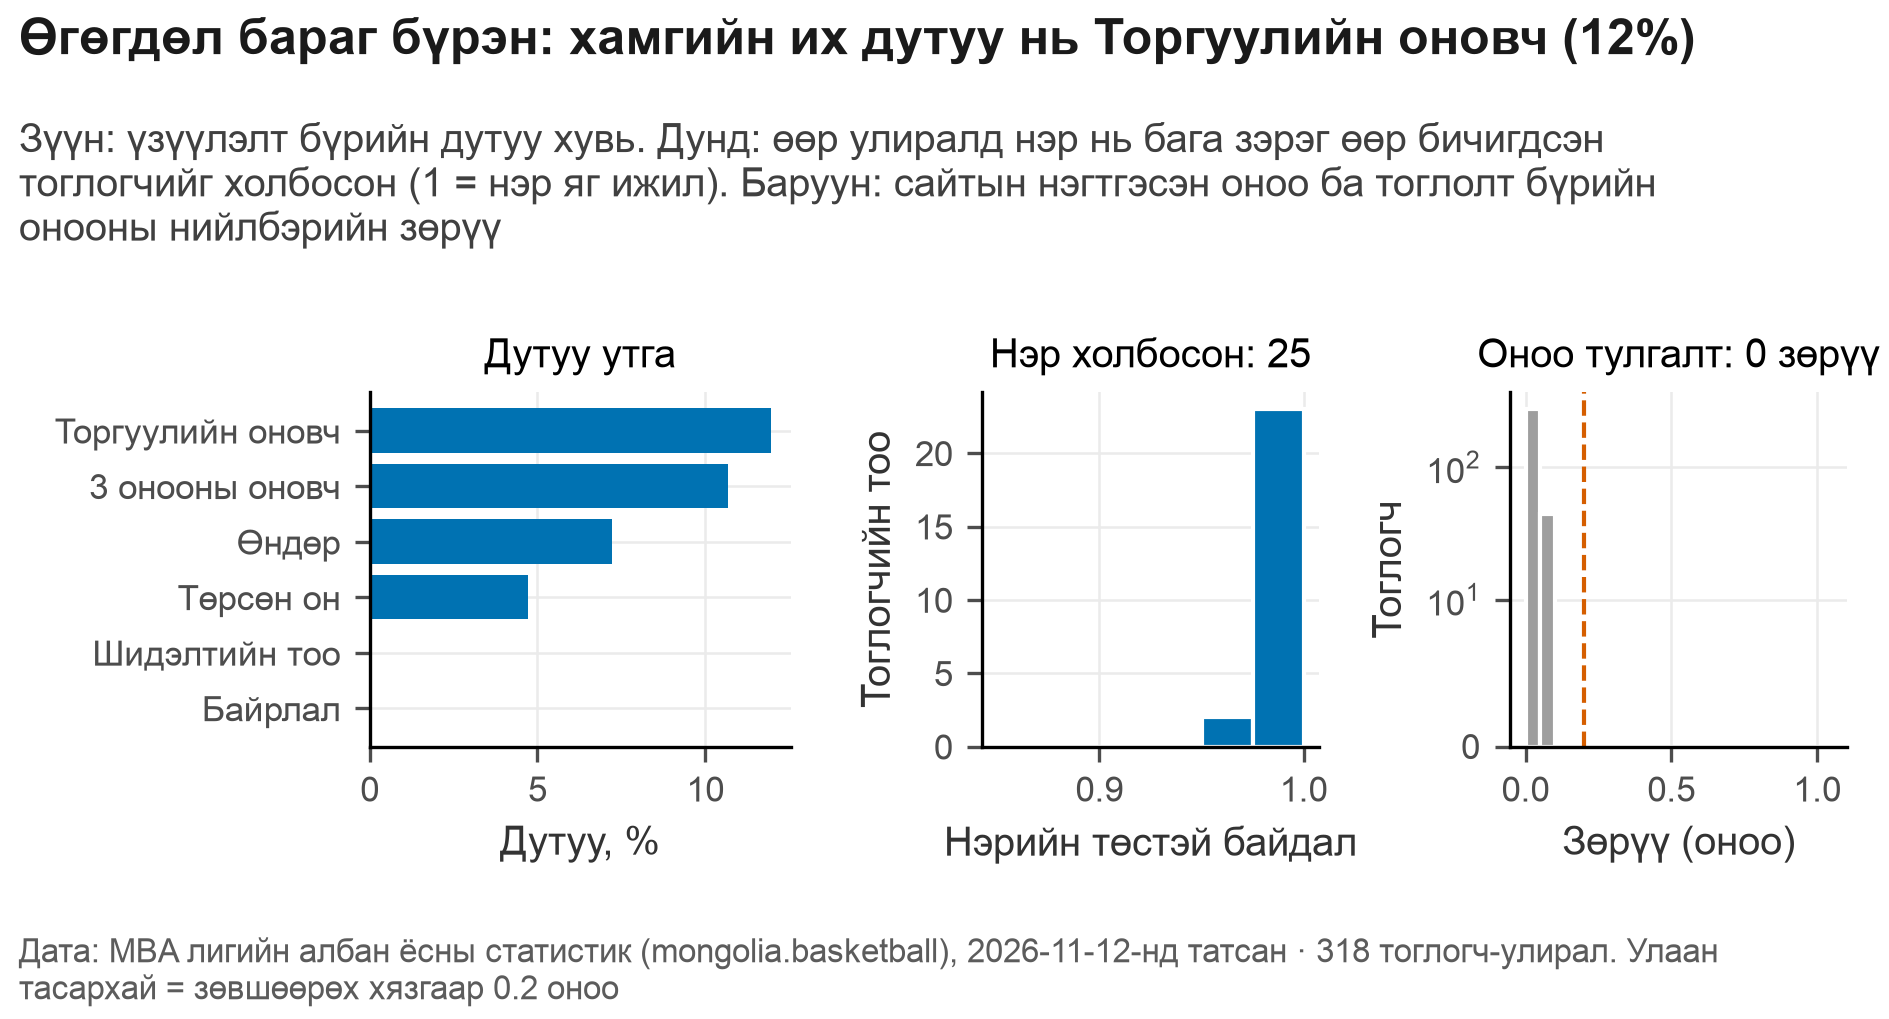

In [4]:
show("U09_data_quality")

## 1. Үндсэн хандлага

In [5]:
pg = pd.read_csv(P / "player_games.csv"); ps = pd.read_csv(P / "players_season.csv")
share = pg.loc[pg.is_import, "PTS"].sum() / pg.PTS.sum()
print(f"Гадаад тоглогч: тоглогчдын {ps.drop_duplicates('player_id').is_import.mean():.0%}, онооны {share:.0%}")
from src.charts.comparison import pareto_table
reg = pg[(pg.phase == "regular") & (pg.season == "2025-2026")]
t = pareto_table(reg.groupby("player_id").PTS.sum()); k = int((t.cum_share < 0.8).sum()) + 1
print(f"2025–26: эхний {k} тоглогч ({k / len(t):.0%}) онооны 80%-ийг авдаг")

Гадаад тоглогч: тоглогчдын 32%, онооны 42%


2025–26: эхний 69 тоглогч (41%) онооны 80%-ийг авдаг


**[Ноорог — өөрийн үгээр дахин бичих]** Дээрх тоогоор лигийн оноо цөөн тоглогчид, ялангуяа гадаад тоглогчид төвлөрдөг эсэхийг өөрийн үгээр бичнэ.

## 2. Хамаарал

In [6]:
h = hyp.set_index("hid")
print(f"Өндөр ба самбарын хамаарлын хүч: {h.loc['H4', 'estimate']:.2f}")
print(f"Оновч бусад хүчин зүйлээс хэр илүү нөлөөтэй (H3): {h.loc['H3', 'estimate']:.2f}")

Өндөр ба самбарын хамаарлын хүч: 0.63
Оновч бусад хүчин зүйлээс хэр илүү нөлөөтэй (H3): 1.92


**[Ноорог — өөрийн үгээр дахин бичих]** Хүчтэй хамааралтай хосууд, ялалтад хамгийн их нөлөөлдөг хүчин зүйлийг тайлбарлана.

## 3. Онцгой утга

In [7]:
g = pd.read_csv(P / "games.csv"); g["margin"] = (g.home_pts - g.away_pts).abs()
q1, q3 = g.margin.quantile([.25, .75]); print("Их зөрүүтэй тоглолт (хайрцган графикийн дүрмээр):")
display(g[g.margin > q3 + 1.5 * (q3 - q1)][["date", "home_team", "away_team", "home_pts", "away_pts", "margin"]])

Их зөрүүтэй тоглолт (хайрцган графикийн дүрмээр):


,date,home_team,away_team,home_pts,away_pts,margin
116,2026-02-03,Bishrelt Metal,Erdenet Miners,54,86,32
121,2026-02-07,BurenScore Mongolians,Khan Falcons,41,120,79
157,2026-03-18,XAC Broncos,Khan Falcons,93,58,35
200,2026-10-15,Darkhan United,Khan Falcons,102,74,28
223,2026-10-28,Darkhan United,Western Warriors,78,50,28
239,2026-11-06,BCH Knights,SUA TLG Tushig Bagana,87,59,28


**[Ноорог — өөрийн үгээр дахин бичих]** Юүлүүр график (U01) дээр гадуурх тоглогчдын ихэнх нь цөөн шидэлттэй — жинхэнэ онцгой ба азыг ялгах.

## 4. Шалтгаан, үр дагавар

**[Ноорог — өөрийн үгээр дахин бичих]** Хамт өөрчлөгдөх нь шалтгаан гэсэн үг биш (гадаад тоглогч илүү олон минут тоглодог). Гэрийн талбайн давуу тал батлагдаагүй (H2) — ихэнх тоглолт нэг заалд болдог.

## 5. Практик санал

**[Ноорог — өөрийн үгээр дахин бичих]** Жишээ: (1) дунд зайн шидэлтийг багасгаж сагсны доор ба булангийн 3 оноо руу шилжүүлэх (F15); (2) дотоод тоглогчийн минутыг нэмэх; (3) цөөн тоглогчоос хамаарал өндөр багуудад (P2) гүнийг нэмэх.